# Quem volta ao telecentro? — OpenLabs no Telecentro

**Global Solution 2026.2 · CitizenTech · Data Science & Statistical Computing**
Equipe 10 · integrantes e RMs em `integrantes.txt`.

O **OpenLabs no Telecentro** leva labs interativos de tecnologia para os computadores públicos dos telecentros.
O planejador de Programação Dinâmica da mesma equipe já diz *aonde ir* e *o que estudar na sessão*.
Este notebook usa os dados das sessões para responder duas perguntas que ajudam o monitor a decidir:

| | pergunta | variável-alvo | modelo |
|---|---|---|---|
| 1 | **Quanto uma pessoa vai tirar no checkpoint do lab?** | `nota` (0 a 10, numérica) | regressão linear |
| 2 | **Essa pessoa vai voltar ao telecentro em até 7 dias?** | `voltou_em_7_dias` (0/1, binária) | regressão logística |

**Por que importa.** Uma nota prevista baixa indica que vale oferecer o *showcase* (o filme guiado) antes da simulação.
Uma probabilidade baixa de retorno indica quem deve receber um lembrete ou uma reserva de computador:
cada pessoa que não volta é uma trilha de estudo interrompida.

**Hipóteses que vamos testar**
- H1: quem usa o showcase e quem já concluiu mais labs tira notas maiores.
- H2: quanto mais minutos de caminhada até o telecentro, menor a chance de voltar.


## 1. Os dados e de onde vieram

`dados/sessoes_telecentro.csv` tem uma linha por sessão de estudo. A base é **simulada** por `gerar_dados.py` (semente 2026), e **não contém dados pessoais reais**. Duas partes vêm de fontes reais:

- **distância a pé** até o telecentro mais próximo: calculada nas ruas reais do centro de São Paulo (© OpenStreetMap contributors, ODbL), pelo Dijkstra multi-fonte do planejador de Programação Dinâmica;
- **labs e minutos estimados**: o catálogo real do OpenLabs.

| coluna | significado |
|---|---|
| `id_sessao`, `id_aluno` | identificadores (uma pessoa tem de 1 a 5 sessões) |
| `telecentro` | telecentro mais próximo da casa da pessoa |
| `idade` | idade em anos (**faltando** em parte do cadastro) |
| `internet_em_casa` | 1 se tem internet boa em casa |
| `distancia_m`, `minutos_caminhada` | distância a pé até o telecentro, e quanto tempo isso leva no passo da pessoa |
| `periodo` | manhã, tarde ou noite |
| `lab`, `handbook`, `minutos_estimados` | o lab estudado e quanto tempo ele costuma levar |
| `labs_concluidos_antes` | quantos labs a pessoa já tinha concluído (nota ≥ 6) |
| `minutos_no_lab` | quanto tempo ficou no lab (**alguns cronômetros ficaram ligados**) |
| `usou_showcase` | 1 se assistiu ao filme guiado antes de simular |
| `nota` | nota do checkpoint, de 0 a 10 — **alvo 1** |
| `voltou_em_7_dias` | 1 se voltou ao telecentro em até 7 dias — **alvo 2** |


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score, accuracy_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
SEMENTE = 42

dados = pd.read_csv("dados/sessoes_telecentro.csv")
print(dados.shape)
dados.head()

(1247, 16)


,id_sessao,id_aluno,telecentro,idade,internet_em_casa,distancia_m,minutos_caminhada,periodo,lab,handbook,minutos_estimados,labs_concluidos_antes,minutos_no_lab,usou_showcase,nota,voltou_em_7_dias
0,1,1,Telecentro República,19.0,0,915,10.7,noite,splunk-ingest,splunk,25,0,27.7,1,6.2,1
1,2,1,Telecentro República,19.0,0,915,10.7,noite,normalize-a-spreadsheet,databases,25,1,32.5,1,7.5,0
2,3,1,Telecentro República,19.0,0,915,10.7,noite,splunk-ingest,splunk,25,2,32.9,1,8.5,0
3,4,2,Telecentro República,26.0,0,546,6.7,tarde,rpn,algorithms,20,0,20.0,0,3.3,1
4,5,2,Telecentro República,26.0,0,546,6.7,tarde,three-pillars,otel,25,0,21.7,1,6.0,1


In [2]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 1247 entries, 0 to 1246
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_sessao              1247 non-null   int64  
 1   id_aluno               1247 non-null   int64  
 2   telecentro             1247 non-null   str    
 3   idade                  1211 non-null   float64
 4   internet_em_casa       1247 non-null   int64  
 5   distancia_m            1247 non-null   int64  
 6   minutos_caminhada      1247 non-null   float64
 7   periodo                1247 non-null   str    
 8   lab                    1247 non-null   str    
 9   handbook               1247 non-null   str    
 10  minutos_estimados      1247 non-null   int64  
 11  labs_concluidos_antes  1247 non-null   int64  
 12  minutos_no_lab         1247 non-null   float64
 13  usou_showcase          1247 non-null   int64  
 14  nota                   1247 non-null   float64
 15  voltou_em_7_dia

In [3]:
dados.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id_sessao,1247.0,624.00,360.12,1.0,312.5,624.0,935.5,1247.0
id_aluno,1247.0,204.68,121.85,1.0,97.0,202.0,310.0,420.0
idade,1211.0,36.60,14.27,14.0,26.0,37.0,46.0,78.0
internet_em_casa,1247.0,0.53,0.50,0.0,0.0,1.0,1.0,1.0
distancia_m,1247.0,1092.69,637.25,45.0,667.5,915.0,1394.0,3087.0
minutos_caminhada,1247.0,14.25,8.42,0.6,8.4,12.0,18.7,38.9
minutos_estimados,1247.0,24.34,4.46,15.0,20.0,25.0,30.0,30.0
labs_concluidos_antes,1247.0,0.44,0.77,0.0,0.0,0.0,1.0,4.0
minutos_no_lab,1247.0,31.79,54.34,5.0,18.8,24.6,30.7,612.0
usou_showcase,1247.0,0.55,0.50,0.0,0.0,1.0,1.0,1.0


## 2. Preparação dos dados

Três problemas aparecem na descrição acima:

1. **`idade` faltando** em parte das linhas. Vamos imputar com a **mediana do treino**, nunca do conjunto inteiro.
2. **`minutos_no_lab` com valores absurdos.** O máximo passa de 600 minutos para labs de 15 a 30. Foi o cronômetro que ficou ligado. A regra é por linha (mais de 4× o tempo estimado vira "desconhecido") e não olha os outros dados, então não vaza informação. O valor desconhecido também é imputado com a mediana do treino.
3. **O tempo no lab só faz sentido comparado ao tamanho do lab.** Criamos `ritmo = minutos_no_lab / minutos_estimados`, em que 1 quer dizer "no tempo esperado".


faltando por coluna:
idade    36
dtype: int64

cronômetro ligado: 23 sessões (1.8%)


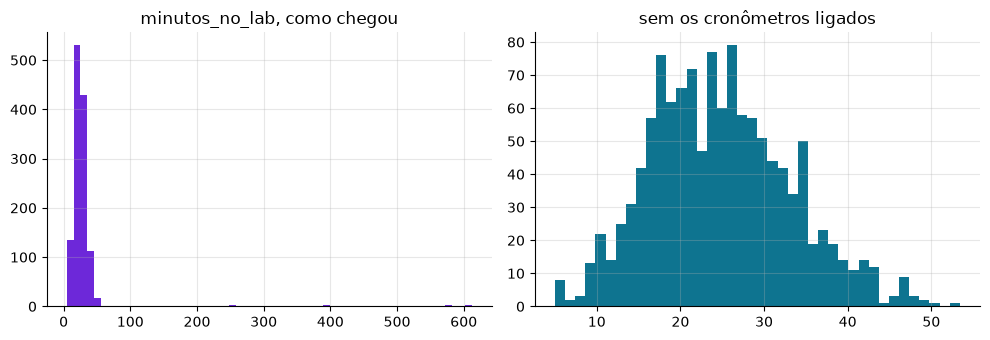

In [4]:
print("faltando por coluna:")
print(dados.isna().sum()[dados.isna().sum() > 0])
absurdo = dados["minutos_no_lab"] > 4 * dados["minutos_estimados"]
print(f"\ncronômetro ligado: {absurdo.sum()} sessões ({absurdo.mean():.1%})")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(dados["minutos_no_lab"], bins=60, color="#6d28d9")
ax[0].set_title("minutos_no_lab, como chegou")
ax[1].hist(dados.loc[~absurdo, "minutos_no_lab"], bins=40, color="#0e7490")
ax[1].set_title("sem os cronômetros ligados")
plt.tight_layout(); plt.show()

In [5]:
def preparar(d: pd.DataFrame) -> pd.DataFrame:
    """Limpeza por linha: não aprende nada dos dados, então pode rodar antes da divisão."""
    d = d.copy()
    d.loc[d["minutos_no_lab"] > 4 * d["minutos_estimados"], "minutos_no_lab"] = np.nan
    d["ritmo"] = d["minutos_no_lab"] / d["minutos_estimados"]
    return d

base = preparar(dados)
base[["minutos_no_lab", "ritmo"]].describe().round(2)

,minutos_no_lab,ritmo
count,1224.00,1224.00
mean,24.84,1.02
std,8.36,0.28
min,5.00,0.20
25%,18.68,0.83
50%,24.30,1.02
75%,30.30,1.21
max,53.40,1.90


### Divisão entre treino e teste, sem vazamento

A mesma pessoa aparece em até 5 sessões. Uma divisão sorteada linha a linha colocaria sessões da mesma pessoa nos dois lados. O teste deixaria de medir o desempenho em pessoas novas. Um modelo capaz de "decorar" a pessoa pareceria melhor do que é.

Por isso dividimos **por pessoa** (`GroupShuffleSplit` por `id_aluno`), com 75% das pessoas no treino e 25% no teste. Toda transformação que *aprende* algo dos dados fica dentro de um `Pipeline`: a mediana da imputação, a média e o desvio da padronização e as categorias do one-hot. Assim, tudo é ajustado **só no treino**.


In [6]:
divisor = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEMENTE)
i_treino, i_teste = next(divisor.split(base, groups=base["id_aluno"]))
treino, teste = base.iloc[i_treino], base.iloc[i_teste]

pessoas_nos_dois = set(treino["id_aluno"]) & set(teste["id_aluno"])
print(f"treino: {len(treino)} sessões de {treino['id_aluno'].nunique()} pessoas")
print(f"teste:  {len(teste)} sessões de {teste['id_aluno'].nunique()} pessoas")
print(f"pessoas nos dois lados: {len(pessoas_nos_dois)}")
assert not pessoas_nos_dois

treino: 922 sessões de 315 pessoas
teste:  325 sessões de 105 pessoas
pessoas nos dois lados: 0


In [7]:
NUMERICAS = ["idade", "minutos_caminhada", "labs_concluidos_antes", "ritmo", "minutos_estimados"]
BINARIAS = ["internet_em_casa", "usou_showcase"]
CATEGORICAS = ["periodo", "handbook"]

def preprocessador(numericas):
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")), ("padronizar", StandardScaler())]), numericas),
        ("bin", "passthrough", BINARIAS),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAS),
    ])

## 3. Regressão linear: prever a nota

**Variáveis de entrada:** tudo o que se sabe até o fim da sessão, *menos* o retorno, que acontece depois. Usar o retorno seria vazamento: é informação do futuro.


In [8]:
X_lin = NUMERICAS + BINARIAS + CATEGORICAS
linear = Pipeline([("prep", preprocessador(NUMERICAS)), ("modelo", LinearRegression())])
linear.fit(treino[X_lin], treino["nota"])
prev_nota = linear.predict(teste[X_lin])

def metricas_regressao(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R²": r2_score(y, p)}

linha_de_base = np.full(len(teste), treino["nota"].mean())
tabela = pd.DataFrame({
    "chutar a média do treino": metricas_regressao(teste["nota"], linha_de_base),
    "regressão linear": metricas_regressao(teste["nota"], prev_nota),
}).T.round(3)
tabela

,MAE,RMSE,R²
chutar a média do treino,1.390,1.723,-0.011
regressão linear,0.844,1.066,0.613


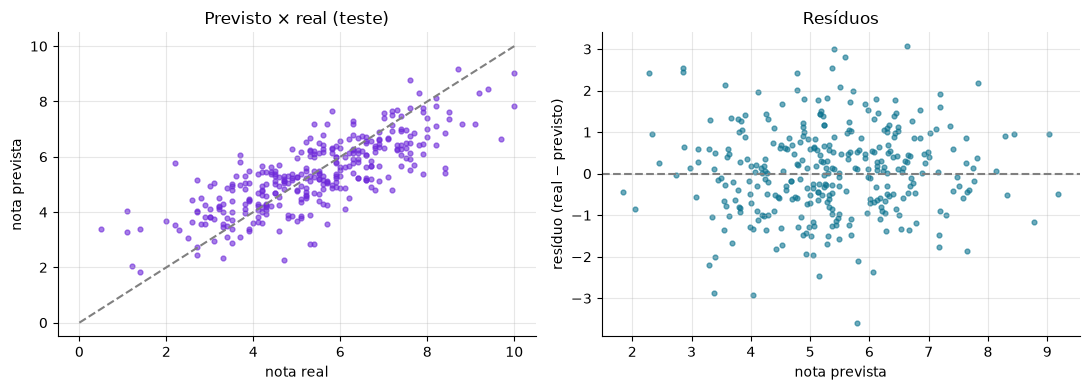

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(teste["nota"], prev_nota, s=12, alpha=0.6, color="#6d28d9")
ax[0].plot([0, 10], [0, 10], "--", color="gray")
ax[0].set(xlabel="nota real", ylabel="nota prevista", title="Previsto × real (teste)")
residuo = teste["nota"] - prev_nota
ax[1].scatter(prev_nota, residuo, s=12, alpha=0.6, color="#0e7490")
ax[1].axhline(0, color="gray", ls="--")
ax[1].set(xlabel="nota prevista", ylabel="resíduo (real − previsto)", title="Resíduos")
plt.tight_layout(); plt.show()

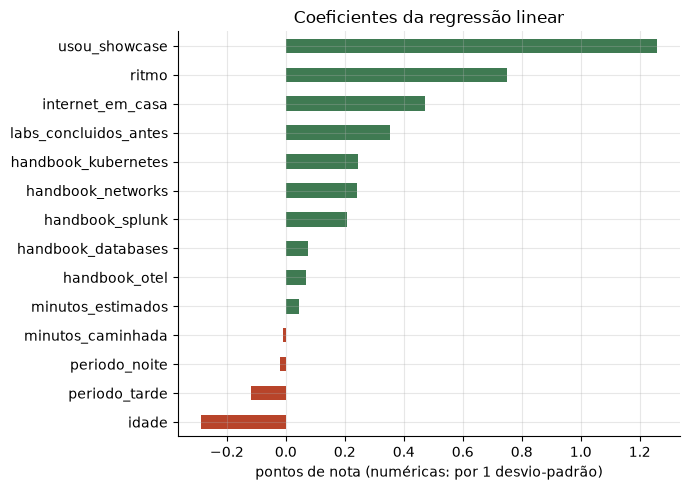

,coeficiente
idade,-0.289
periodo_tarde,-0.117
periodo_noite,-0.021
minutos_caminhada,-0.010
minutos_estimados,0.044
handbook_otel,0.069
handbook_databases,0.075
handbook_splunk,0.208
handbook_networks,0.240
handbook_kubernetes,0.245


In [10]:
nomes = linear.named_steps["prep"].get_feature_names_out()
coef = pd.Series(linear.named_steps["modelo"].coef_, index=[n.split("__")[1] for n in nomes]).sort_values()
ax = coef.plot.barh(figsize=(7, 5), color=["#b8442a" if c < 0 else "#3f7a52" for c in coef])
ax.set(title="Coeficientes da regressão linear", xlabel="pontos de nota (numéricas: por 1 desvio-padrão)")
plt.tight_layout(); plt.show()
coef.round(3).to_frame("coeficiente")

In [11]:
prep_lin = linear.named_steps["prep"]
desvios = dict(zip(NUMERICAS, prep_lin.named_transformers_["num"].named_steps["padronizar"].scale_))
print(f"usar o showcase:          {coef['usou_showcase']:+.2f} ponto(s) de nota")
print(f"cada lab já concluído:    {coef['labs_concluidos_antes'] / desvios['labs_concluidos_antes']:+.2f} ponto(s)")
print(f"ritmo +0,1 (10% a mais):  {0.1 * coef['ritmo'] / desvios['ritmo']:+.2f} ponto(s)")
print(f"internet em casa:         {coef['internet_em_casa']:+.2f} ponto(s)")
print(f"10 anos a mais de idade:  {10 * coef['idade'] / desvios['idade']:+.2f} ponto(s)")

usar o showcase:          +1.26 ponto(s) de nota
cada lab já concluído:    +0.47 ponto(s)
ritmo +0,1 (10% a mais):  +0.27 ponto(s)
internet em casa:         +0.47 ponto(s)
10 anos a mais de idade:  -0.20 ponto(s)


**Interpretação.**
- O modelo erra a nota em **menos de 1 ponto** em média (MAE, na escala de 0 a 10). Chutar a média do treino erra cerca de 65% mais. O R² diz que o modelo explica perto de 60% da variação das notas de pessoas que ele nunca viu.
- **H1 se sustenta.** Usar o showcase e já ter concluído labs puxam a nota para cima. Ficar no lab o tempo esperado, sem correr, também ajuda.
- Os resíduos não mostram curva nem funil fortes, então uma reta é uma aproximação razoável.
- O que sobra de erro vem do que o dado não mede: motivação, cansaço, quem ajudou ao lado. Nenhum modelo com estas colunas chega a erro zero, e é honesto dizer isso.


## 4. Regressão logística: a pessoa vai voltar?

Aqui a `nota` pode entrar como variável. Ela é conhecida no fim da sessão, antes da janela de 7 dias. O `id_aluno` nunca entra, e a divisão por pessoa continua valendo.


In [12]:
NUMERICAS_LOG = NUMERICAS + ["nota"]
X_log = NUMERICAS_LOG + BINARIAS + CATEGORICAS
logistica = Pipeline([("prep", preprocessador(NUMERICAS_LOG)), ("modelo", LogisticRegression(max_iter=1000, tol=1e-8))])
logistica.fit(treino[X_log], treino["voltou_em_7_dias"])
prob = logistica.predict_proba(teste[X_log])[:, 1]
y = teste["voltou_em_7_dias"]

print(f"taxa de retorno no treino: {treino['voltou_em_7_dias'].mean():.1%} · no teste: {y.mean():.1%}")

def metricas_classificacao(y, p):
    return {"acurácia": accuracy_score(y, p), "precisão": precision_score(y, p, zero_division=0),
            "recall": recall_score(y, p), "F1": f1_score(y, p)}

maioria = np.zeros(len(y), dtype=int)  # a classe mais comum: "não volta"
pd.DataFrame({
    "chutar sempre 'não volta'": metricas_classificacao(y, maioria),
    "logística, corte 0,5": metricas_classificacao(y, (prob >= 0.5).astype(int)),
}).T.round(3)

taxa de retorno no treino: 38.3% · no teste: 46.5%


,acurácia,precisão,recall,F1
chutar sempre 'não volta',0.535,0.000,0.000,0.000
"logística, corte 0,5",0.702,0.737,0.556,0.634


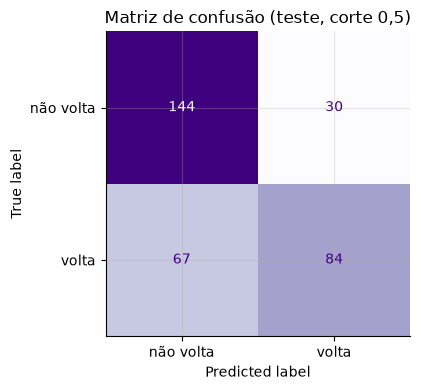

In [13]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y, prob >= 0.5), display_labels=["não volta", "volta"]).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_title("Matriz de confusão (teste, corte 0,5)")
plt.tight_layout(); plt.show()

**Que erro custa mais?** O que se faz com quem *não vai voltar* é barato: um lembrete por SMS ou WhatsApp e um computador reservado. Deixar de avisar quem ia sumir custa uma trilha interrompida. Então **o recall da classe "não volta" importa mais que a precisão**. Abaixo, a mesma probabilidade com vários cortes, olhando a classe que interessa à ação.


In [14]:
linhas = []
for corte in np.arange(0.30, 0.71, 0.05):
    nao_volta_prev = (prob < corte).astype(int)
    nao_volta_real = (y == 0).astype(int)
    linhas.append({"corte": round(corte, 2), "avisados": int(nao_volta_prev.sum()),
                   "precisão (não volta)": precision_score(nao_volta_real, nao_volta_prev, zero_division=0),
                   "recall (não volta)": recall_score(nao_volta_real, nao_volta_prev),
                   "F1 (não volta)": f1_score(nao_volta_real, nao_volta_prev)})
cortes = pd.DataFrame(linhas).set_index("corte").round(3)
cortes

,avisados,precisão (não volta),recall (não volta),F1 (não volta)
corte,,,,
0.30,112,0.821,0.529,0.643
0.35,135,0.800,0.621,0.699
0.40,157,0.764,0.690,0.725
0.45,180,0.722,0.747,0.734
0.50,211,0.682,0.828,0.748
0.55,242,0.657,0.914,0.764
0.60,265,0.626,0.954,0.756
0.65,277,0.606,0.966,0.745
0.70,293,0.587,0.989,0.737


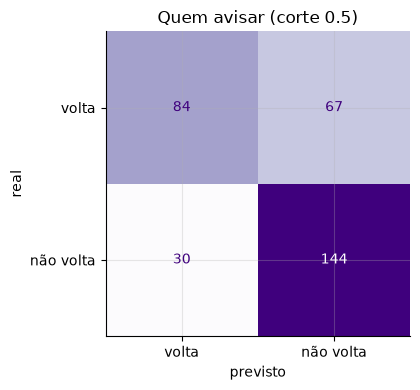

com corte 0.5: avisamos 211 de 325 sessões; recall de quem não volta = 82.8%, precisão = 68.2%


In [15]:
CORTE = 0.50
nao_volta_prev = prob < CORTE
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y == 0, nao_volta_prev), display_labels=["volta", "não volta"]).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set(title=f"Quem avisar (corte {CORTE})", xlabel="previsto", ylabel="real")
plt.tight_layout(); plt.show()
print(f"com corte {CORTE}: avisamos {nao_volta_prev.sum()} de {len(y)} sessões; "
      f"recall de quem não volta = {recall_score(y == 0, nao_volta_prev):.1%}, precisão = {precision_score(y == 0, nao_volta_prev):.1%}")

In [16]:
nomes = logistica.named_steps["prep"].get_feature_names_out()
coef_log = pd.Series(logistica.named_steps["modelo"].coef_[0], index=[n.split("__")[1] for n in nomes]).sort_values()
razao = np.exp(coef_log).round(2)
pd.DataFrame({"coeficiente (log-odds)": coef_log.round(3), "razão de chances": razao})

,coeficiente (log-odds),razão de chances
minutos_caminhada,-0.522,0.59
handbook_kubernetes,-0.513,0.60
internet_em_casa,-0.407,0.67
periodo_noite,-0.372,0.69
minutos_estimados,-0.107,0.90
handbook_splunk,-0.096,0.91
usou_showcase,-0.093,0.91
handbook_databases,-0.092,0.91
idade,0.009,1.01
ritmo,0.021,1.02


**Interpretação.**
- O modelo supera o chute da classe mais comum em todas as métricas. A escolha do corte é uma decisão de política, não de estatística. Subir o corte avisa mais gente: com 0,55, três em cada quatro sessões recebem aviso, o que deixa de ser uma ação dirigida. Com **0,50**, o telecentro alcança mais de 80% de quem não ia voltar, e dois em cada três avisos acertam.
- **H2 se sustenta.** `minutos_caminhada` tem o efeito negativo mais forte. Cada desvio-padrão a mais de caminhada (cerca de 8 minutos) multiplica as chances de voltar por cerca de 0,6. Nota alta puxa o retorno para cima, e o período da noite e ter internet em casa puxam para baixo.
- **Cuidado com o que parece forte.** `handbook_kubernetes` tem um coeficiente quase tão grande quanto o da caminhada, mas vem de poucas sessões, e o gerador não tem nenhuma regra ligada ao handbook. É ruído. Com amostras pequenas por categoria, um coeficiente grande não é uma descoberta.


## 5. Do modelo para a decisão

Usamos o modelo para comparar cenários: as mesmas pessoas do teste, mudando uma coisa só.


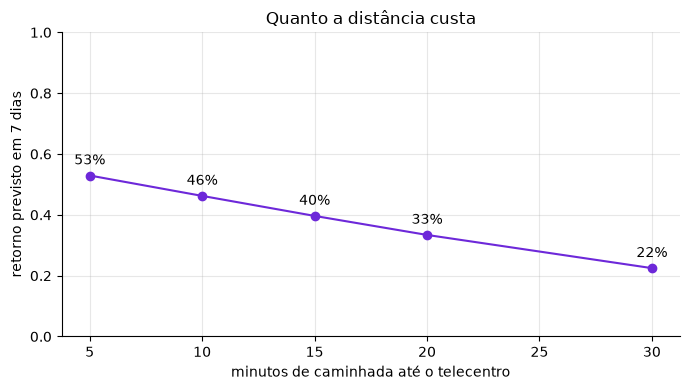

In [17]:
def media_prevista(**mudar):
    d = teste.copy()
    for coluna, valor in mudar.items():
        d[coluna] = valor
    return logistica.predict_proba(d[X_log])[:, 1].mean()

caminhadas = [5, 10, 15, 20, 30]
retorno = [media_prevista(minutos_caminhada=m) for m in caminhadas]
fig, ax = plt.subplots()
ax.plot(caminhadas, retorno, "o-", color="#6d28d9")
ax.set(xlabel="minutos de caminhada até o telecentro", ylabel="retorno previsto em 7 dias", title="Quanto a distância custa", ylim=(0, 1))
for m, p in zip(caminhadas, retorno):
    ax.annotate(f"{p:.0%}", (m, p), textcoords="offset points", xytext=(0, 8), ha="center")
plt.tight_layout(); plt.show()

In [18]:
nota_sem = linear.predict(teste[X_lin].assign(usou_showcase=0)).mean()
nota_com = linear.predict(teste[X_lin].assign(usou_showcase=1)).mean()
ret_sem = media_prevista(nota=linear.predict(teste[X_lin].assign(usou_showcase=0)))
ret_com = media_prevista(nota=linear.predict(teste[X_lin].assign(usou_showcase=1)))
longe = teste["minutos_caminhada"] > 20
print(f"nota média prevista: sem showcase {nota_sem:.2f} · com showcase {nota_com:.2f}")
print(f"retorno previsto (pela nota): sem showcase {ret_sem:.1%} · com showcase {ret_com:.1%}")
print(f"{longe.mean():.0%} das sessões de teste são de quem anda mais de 20 min; retorno real delas: {y[longe].mean():.1%} contra {y[~longe].mean():.1%} das outras")

nota média prevista: sem showcase 4.65 · com showcase 5.91
retorno previsto (pela nota): sem showcase 34.3% · com showcase 45.4%
21% das sessões de teste são de quem anda mais de 20 min; retorno real delas: 22.1% contra 52.9% das outras


### Exportar para o OpenLabs

O lab *Who comes back* do OpenLabs refaz estes dois modelos no navegador. Para ser **a mesma análise**, ele usa a mesma divisão por pessoa, e o teste do pacote `ds-domain` confere que os coeficientes e as métricas batem com os do scikit-learn. Esta célula grava essa referência.


In [19]:
import json

def coeficientes(pipe):
    nomes = [n.split("__")[1] for n in pipe.named_steps["prep"].get_feature_names_out()]
    m = pipe.named_steps["modelo"]
    w = m.coef_[0] if m.coef_.ndim == 2 else m.coef_
    b = float(np.ravel(m.intercept_)[0])
    return {"intercepto": b, **{n: float(c) for n, c in zip(nomes, w)}}

referencia = {
    "pessoas_no_teste": sorted(int(i) for i in teste["id_aluno"].unique()),
    "linear": {"variaveis": X_lin, "coeficientes": coeficientes(linear), **{k: float(v) for k, v in metricas_regressao(teste["nota"], prev_nota).items()}},
    "logistica": {"variaveis": X_log, "coeficientes": coeficientes(logistica), **{k: float(v) for k, v in metricas_classificacao(y, (prob >= 0.5).astype(int)).items()}},
}
with open("dados/referencia_openlabs.json", "w", encoding="utf-8") as f:
    json.dump(referencia, f, ensure_ascii=False, indent=1)
print(f"{len(referencia['pessoas_no_teste'])} pessoas no teste; R² {referencia['linear']['R²']:.3f}; F1 {referencia['logistica']['F1']:.3f}")

105 pessoas no teste; R² 0.613; F1 0.634


## 6. Recomendações

1. **Lembrete e reserva para quem tem baixa chance de voltar.** No fim de cada sessão, o sistema calcula a probabilidade de retorno. Abaixo de 0,50, o monitor envia um lembrete e oferece um horário reservado. É barato e atinge a maior parte de quem sumiria (recall acima). **Como medir:** a taxa de retorno em 7 dias dos avisados, comparada a um grupo sorteado que não recebe aviso.
2. **Showcase primeiro para quem a nota prevista é baixa.** O showcase sobe a nota prevista em cerca de 1,3 ponto e, pela nota, também o retorno. Para quem está no começo da trilha (`labs_concluidos_antes = 0`), o OpenLabs deve abrir o lab no showcase, e não na simulação.
3. **A distância é o fator mais forte, e o planejador de PD sabe onde ela pesa.** Quem anda mais de 20 minutos volta bem menos. Essas pessoas devem receber sessões mais longas e menos frequentes (a mochila de 90 min do planejador), ou um novo ponto de acesso perto delas. O indicador de cobertura do planejador mostra quantos cruzamentos ficam a até 15 minutos a pé, e pode ser recalculado para cada lugar candidato.
4. **Horário da noite.** O retorno é menor à noite. Vale testar sessões noturnas mais curtas, com a trilha salva no banco do telecentro (`T_PROGRESSO`) para continuar de onde parou.

### Limitações

- **Os dados são simulados.** As regras que os geraram estão em `gerar_dados.py`. O que este notebook mostra é que os modelos *recuperam* essas regras e como usá-los. Os números não descrevem telecentros reais. O próximo passo é coletar as mesmas colunas das tabelas `T_PROGRESSO` e `T_TENTATIVA` do banco, com consentimento, e refazer a análise.
- **Correlação não é causa.** "O showcase sobe a nota" é o que o modelo associa, e quem escolhe assistir pode ser justamente quem está mais motivado: a variável `engajamento`, que o gerador usa e a base não mostra. Só um experimento (oferecer o showcase por sorteio) separa as duas coisas.
- **Linear e logístico são aproximações.** A nota é limitada a 0–10 e o efeito da caminhada pode não ser constante. Modelos mais flexíveis podem errar menos, mas perdem a leitura direta dos coeficientes, que é o que o monitor usa para decidir.
- **Equidade.** Idade e internet em casa entram no modelo. O aviso deve servir para *oferecer mais* (lembrete, reserva, acompanhamento), nunca para negar vaga ou priorizar quem tem mais chance de voltar.

### Impacto esperado (ODS 4, 10 e 11)

Mais pessoas terminando trilhas no telecentro (ODS 4), atenção dirigida a quem mora mais longe e a quem tem menos acesso em casa (ODS 10), e decisões sobre onde abrir pontos de acesso apoiadas em dados da cidade (ODS 11).
